# ML Assignment 2 - Classification Models and Streamlit Deployment

**Course:** Machine Learning | M.Tech AIML | BITS Pilani  
**Student ID:** 2026ak05169  

I try to predict which telecom customers are likely to churn, using the Telco Customer Churn dataset from Kaggle. I train 5 classification models, compare them on 6 metrics (Accuracy, AUC, Precision, Recall, F1, MCC), save the trained models and create the files needed to deploy the Streamlit app.

**Dataset chosen:** Telco Customer Churn - 20 columns, 7043 instances, binary classification (Churn: Yes/No).

## Steps I Followed

1. Install libraries and load the Telco Customer Churn data from Kaggle
2. EDA: summary statistics and 6 charts
3. Preprocessing: one-hot encoding, removing duplicate dummies, log of TotalCharges, stratified 80/20 split, scaling
4. Hyperparameter tuning (GridSearchCV, 5-fold stratified, MCC scoring) and training of the 5 models
5. Evaluation on train and test (6 metrics), confusion matrices and learning curves
6. Observations and winner, then saving the models, test_data.csv, app.py, requirements.txt and README.md

In [0]:
# Install the libraries used in this notebook 
%pip install numpy pandas matplotlib seaborn scikit-learn joblib kagglehub -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, matthews_corrcoef,
    confusion_matrix
)
from sklearn.metrics import make_scorer

# Folder where the models, test_data.csv, app.py, requirements.txt and README.md are written
volume_dir = "/Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project"
project_dir = volume_dir if os.path.isdir("/Volumes/ebi_eads") else "assignment2_project"
model_dir = os.path.join(project_dir, "model")
os.makedirs(model_dir, exist_ok=True)

print("All libraries imported successfully")
print(f"Project files will be saved to: {project_dir}")

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
All libraries imported successfully
Project files will be saved to: /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project


In [0]:
# Load the Telco Customer Churn dataset from Kaggle
# URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
# 20 columns, 7043 instances, binary classification (Churn: Yes/No)
# if the Kaggle download fails, I load a public copy of the same csv instead

raw_df = None
try:
    import kagglehub
    dataset_path = kagglehub.dataset_download('blastchar/telco-customer-churn')
    csv_files = [f for f in os.listdir(dataset_path) if f.endswith('.csv')]
    raw_df = pd.read_csv(os.path.join(dataset_path, csv_files[0]))
    print("Loaded directly from Kaggle (kagglehub)")
except Exception as e:
    print(f"Kaggle download failed: {e}")

if raw_df is None:
    print("Loading from public mirror (same Telco Customer Churn dataset)...")
    url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
    raw_df = pd.read_csv(url)
    print("Loaded from public mirror")

print("\nDataset: Telco Customer Churn")
print("Source: https://www.kaggle.com/datasets/blastchar/telco-customer-churn")
print(f"Columns: {raw_df.shape[1]}, Instances: {raw_df.shape[0]}")
print("Target: Churn (Yes/No) - binary classification")
print(f"\nColumn names: {list(raw_df.columns)}")

Loaded directly from Kaggle (kagglehub)

Dataset: Telco Customer Churn
Source: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Columns: 21, Instances: 7043
Target: Churn (Yes/No) - binary classification

Column names: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [0]:
# First a basic look at the data before any modelling
# checking shape, first rows, data types, churn split and missing values

print("Shape of dataset:", raw_df.shape)
print("\nFirst 5 rows:")
display(raw_df.head())

print("\nData types and non-null counts:")
print(raw_df.info())

print("\nTarget distribution (Churn):")
counts = raw_df['Churn'].value_counts()
print(counts)
print(f"  No (stayed): {counts.get('No', 0)} ({counts.get('No', 0)/len(raw_df)*100:.1f}%)")
print(f"  Yes (churned): {counts.get('Yes', 0)} ({counts.get('Yes', 0)/len(raw_df)*100:.1f}%)")

print(f"\nMissing values: {raw_df.isnull().sum().sum()}")

print("\nStatistical summary of numeric columns (count, mean, std, min, 25%, 50%, 75%, max):")
# reset_index() so the stat names (count, mean, std, min, ...) show up as a column - display() hides the index
num_stats = raw_df.describe().reset_index().rename(columns={'index': 'Statistic'})
display(num_stats)

print("\nStatistical summary of categorical columns (count, unique, top, freq):")
# these columns mix numbers (count/unique/freq) and text (top), display() fails on that so I convert to string
cat_stats = raw_df.describe(include=['object']).reset_index().rename(columns={'index': 'Statistic'}).astype(str)
display(cat_stats)

print("\nValue counts for key categorical features:")
for col in ['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']:
    print(f"\n{col}:")
    print(raw_df[col].value_counts())

Shape of dataset: (7043, 21)

First 5 rows:


customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paperless

Statistic,SeniorCitizen,tenure,MonthlyCharges
count,7043.0,7043.0,7043.0
mean,0.1621468124378816,32.37114865824223,64.76169246059918
std,0.3686116056100131,24.55948102309446,30.090047097678493
min,0.0,0.0,18.25
25%,0.0,9.0,35.5
50%,0.0,29.0,70.35
75%,0.0,55.0,89.85
max,1.0,72.0,118.75



Statistical summary of categorical columns (count, unique, top, freq):


Statistic,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174



Value counts for key categorical features:

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaperlessBilling:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


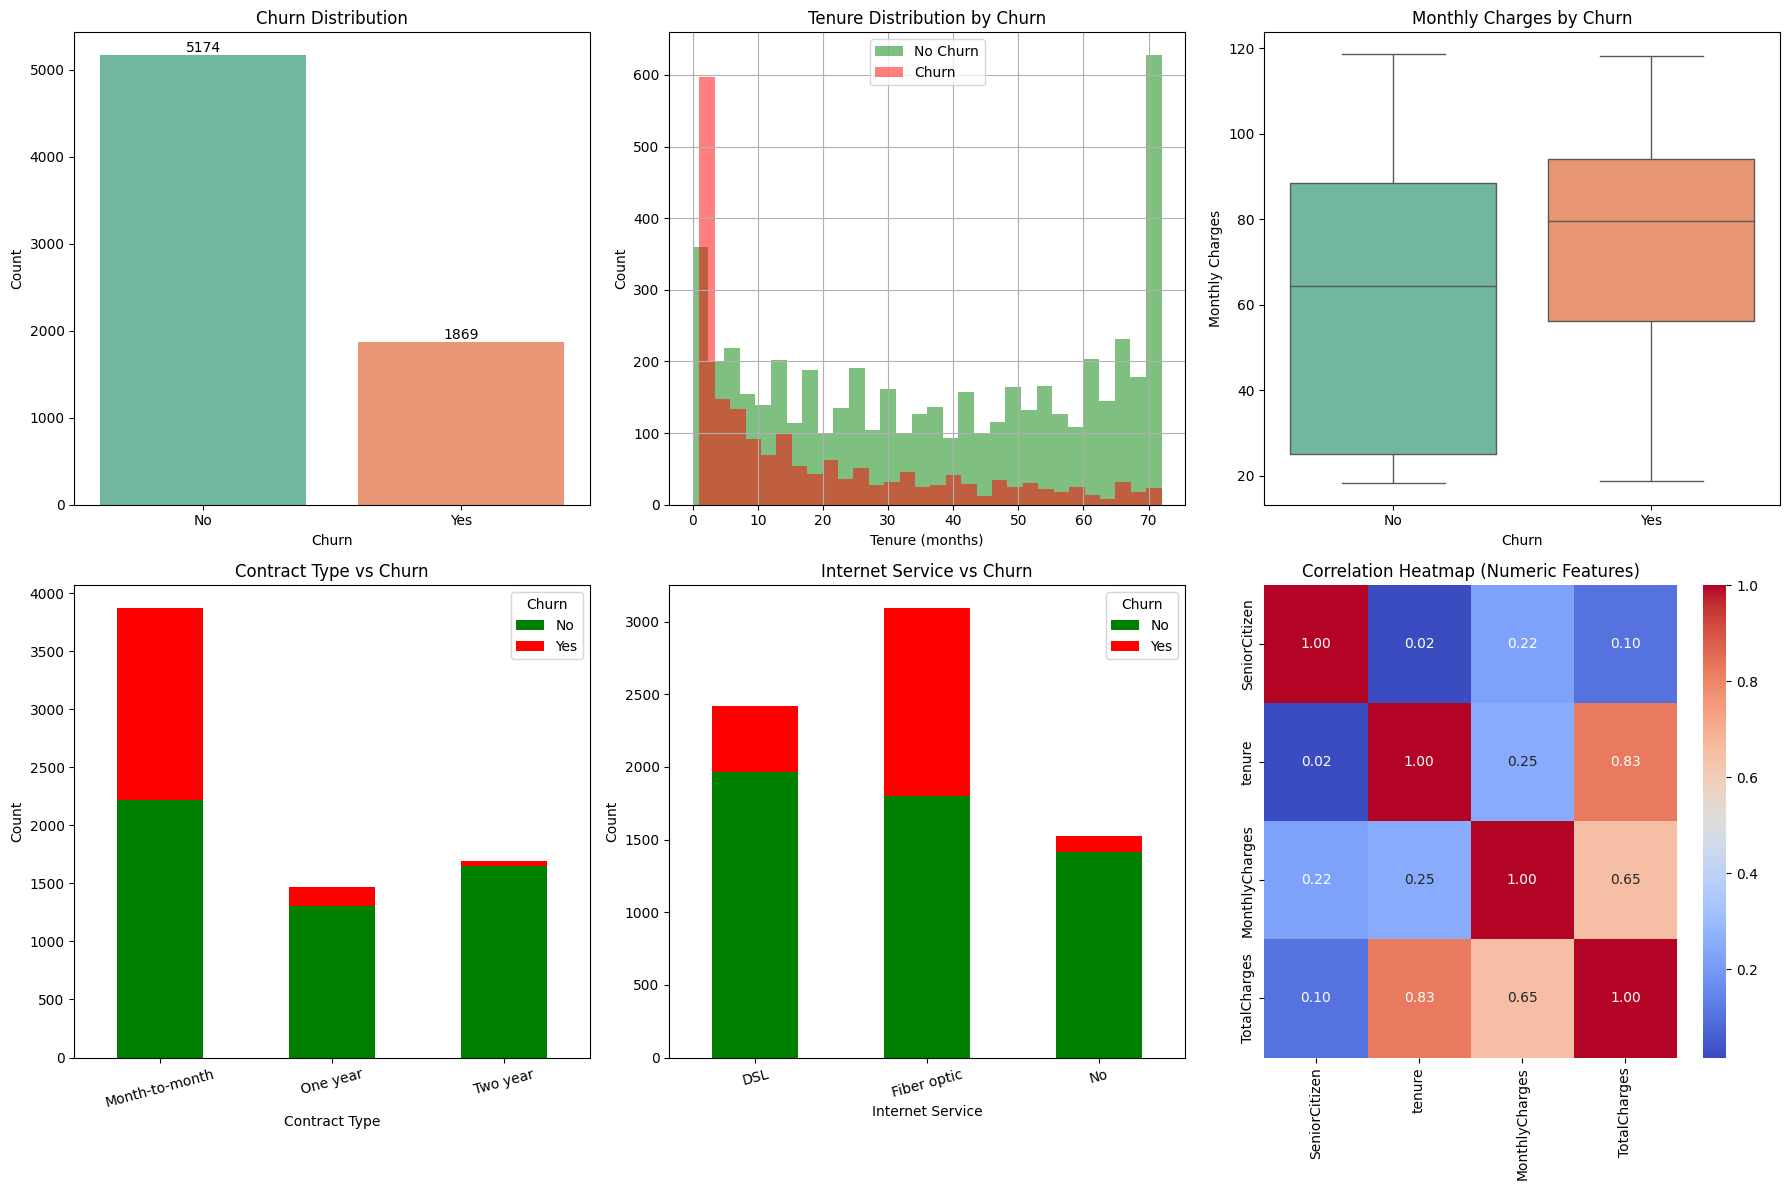

In [0]:
# EDA charts - to see which features look related to churn before I build any model

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Churn distribution (count plot)
ax = axes[0, 0]
sns.barplot(x=raw_df['Churn'].value_counts().index, y=raw_df['Churn'].value_counts().values, palette='Set2', ax=ax)
ax.set_title('Churn Distribution')
ax.set_xlabel('Churn')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')

# 2. Tenure distribution by churn (overlapping histograms)
ax = axes[0, 1]
raw_df[raw_df['Churn']=='No']['tenure'].hist(bins=30, alpha=0.5, label='No Churn', ax=ax, color='green')
raw_df[raw_df['Churn']=='Yes']['tenure'].hist(bins=30, alpha=0.5, label='Churn', ax=ax, color='red')
ax.set_title('Tenure Distribution by Churn')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Count')
ax.legend()

# 3. MonthlyCharges by churn (box plot)
ax = axes[0, 2]
sns.boxplot(data=raw_df, x='Churn', y='MonthlyCharges', ax=ax, palette='Set2')
ax.set_title('Monthly Charges by Churn')
ax.set_xlabel('Churn')
ax.set_ylabel('Monthly Charges')

# 4. Contract type vs churn (stacked bar chart)
ax = axes[1, 0]
contract_churn = pd.crosstab(raw_df['Contract'], raw_df['Churn'])
contract_churn.plot(kind='bar', stacked=True, ax=ax, color=['green', 'red'])
ax.set_title('Contract Type vs Churn')
ax.set_xlabel('Contract Type')
ax.set_ylabel('Count')
ax.legend(title='Churn')
ax.tick_params(axis='x', rotation=15)

# 5. InternetService vs churn (stacked bar chart)
ax = axes[1, 1]
internet_churn = pd.crosstab(raw_df['InternetService'], raw_df['Churn'])
internet_churn.plot(kind='bar', stacked=True, ax=ax, color=['green', 'red'])
ax.set_title('Internet Service vs Churn')
ax.set_xlabel('Internet Service')
ax.set_ylabel('Count')
ax.legend(title='Churn')
ax.tick_params(axis='x', rotation=15)

# 6. Correlation heatmap of numeric features
ax = axes[1, 2]
numeric_cols = raw_df[['SeniorCitizen', 'tenure', 'MonthlyCharges']].copy()
numeric_cols['TotalCharges'] = pd.to_numeric(raw_df['TotalCharges'], errors='coerce')
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Correlation Heatmap (Numeric Features)')

plt.tight_layout()
plt.show()


### Dataset Observations

- The Telco Customer Churn dataset has 20 columns (customerID + 18 features + Churn target) and 7043 instances
- After dropping customerID and one-hot encoding, I got 30 columns. 7 of them turned out to be exact copies of other columns (the 6 '_No internet service' dummies copy InternetService_No, and 'MultipleLines_No phone service' is just 1 - PhoneService_Yes), so I dropped them and kept 23 features
- TotalCharges is right-skewed, so I applied log1p to it before scaling
- Features include both numeric (tenure, MonthlyCharges, TotalCharges) and categorical (Contract, PaymentMethod, InternetService, etc.)
- TotalCharges had 11 blank values, all for new customers with 0 tenure, so I filled them with 0
- Target is binary: about 73.5% of customers stayed and 26.5% churned, so the classes are imbalanced

### Key EDA Insights
- Customers with month-to-month contracts have a higher churn rate compared to long-term contracts
- Customers with fiber optic internet service churn more than DSL or no internet
- Newer customers (low tenure) are more likely to churn
- Higher monthly charges are associated with higher churn
- Tenure and TotalCharges are strongly correlated (0.83), which makes sense since a longer tenure means more total charges

In [0]:
# Preprocessing - most columns are text categories, so they need encoding before training

# Step 1: Drop customerID - it is just an identifier, not useful for prediction
df = raw_df.drop('customerID', axis=1)

# Step 2: Convert TotalCharges to numeric
# Some rows have empty strings in TotalCharges (new customers with 0 tenure)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Step 3: Encode the target (Churn: No -> 0, Yes -> 1)
df['target'] = df['Churn'].map({'No': 0, 'Yes': 1})
df = df.drop('Churn', axis=1)

# Step 4: One-hot encode the categorical columns
# drop_first=True so I don't get one redundant column for every category
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical columns to encode: {categorical_cols}")
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

# Separate features and target
y = df_encoded['target']
X = df_encoded.drop('target', axis=1)
print(f"\nColumns right after one-hot encoding: {X.shape[1]}")

# Step 4b: Remove duplicate dummy columns
# While checking the encoded columns I noticed the 6 '<service>_No internet service' columns are
# exactly the same as InternetService_No, and 'MultipleLines_No phone service' is just 1 - PhoneService_Yes.
# They add nothing new, KNN would count the same info several times, and Naive Bayes assumes
# independent features - so I drop them
redundant_cols = [c for c in X.columns if c.endswith('_No internet service')] + ['MultipleLines_No phone service']
for c in redundant_cols:
    if c.endswith('_No internet service'):
        assert (X[c] == X['InternetService_No']).all()
assert (X['MultipleLines_No phone service'] == 1 - X['PhoneService_Yes']).all()
X = X.drop(columns=redundant_cols)
print(f"Dropped {len(redundant_cols)} duplicate columns: {redundant_cols}")

# Step 4c: log1p on TotalCharges - it has a long right tail, the log makes it closer to a
# bell shape (helps Gaussian Naive Bayes) and reduces the effect of very large values
X['TotalCharges'] = np.log1p(X['TotalCharges'])
print("Applied log1p to TotalCharges")

print(f"\nFinal number of features: {X.shape[1]} columns")
print(f"Instances: {X.shape[0]}")

# Step 5: 80/20 train-test split
# stratify=y keeps the same churn ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Step 6: StandardScaler - KNN and SVM work on distances, so all features need the same scale
# (fit on train only, then applied to test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# back to DataFrames so the column names are kept
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

print("Features scaled using StandardScaler (mean=0, std=1)")
print("Scaler fitted on training data only to prevent data leakage")

Categorical columns to encode: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Columns right after one-hot encoding: 30
Dropped 7 duplicate columns: ['OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service', 'MultipleLines_No phone service']
Applied log1p to TotalCharges

Final number of features: 23 columns
Instances: 7043

Training set: 5634 samples
Test set: 1409 samples
Features scaled using StandardScaler (mean=0, std=1)
Scaler fitted on training data only to prevent data leakage


In [0]:
# Hyperparameter tuning: GridSearchCV with 5-fold StratifiedKFold
# Stratified keeps the 73.5 / 26.5 churn ratio in every fold
# Scoring = MCC, the same metric I use later to pick the winner
# class_weight='balanced' is in the grid for LR, DT and SVM so they don't just lean towards No Churn


mcc_scorer = make_scorer(matthews_corrcoef)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Hyperparameter tuning with 5-fold Stratified Cross-Validation")
print("Scoring metric: MCC (same metric used to pick the winner)")
print("=" * 70)

# KNN: small k overfits, large k underfits (sklearn KNN has no class_weight option)
print("\n[1/5] Tuning KNN...")
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={'n_neighbors': [11, 15, 21, 25, 31, 41],
                'weights': ['uniform', 'distance'],
                'metric': ['euclidean', 'manhattan']},
    cv=cv_strategy, scoring=mcc_scorer, n_jobs=-1, verbose=0
)
knn_grid.fit(X_train_scaled, y_train)
print(f"  Best params : {knn_grid.best_params_}")
print(f"  Best CV MCC : {knn_grid.best_score_:.4f}")

# SVM: C = regularization strength, gamma = how far one point's influence reaches
print("\n[2/5] Tuning SVM (this takes a bit longer due to RBF kernel)...")
svm_grid = GridSearchCV(
    SVC(kernel='rbf', random_state=42),
    param_grid={'C': [0.5, 1, 2, 5], 'gamma': ['scale', 'auto'],
                'class_weight': [None, 'balanced']},
    cv=cv_strategy, scoring=mcc_scorer, n_jobs=-1, verbose=0
)
svm_grid.fit(X_train_scaled, y_train)
print(f"  Best params : {svm_grid.best_params_}")
print(f"  Best CV MCC : {svm_grid.best_score_:.4f}")

# Decision Tree: max_depth and min_samples_leaf stop the tree from memorizing the training data
print("\n[3/5] Tuning Decision Tree...")
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={'max_depth': [3, 5, 7, 10, None], 'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 5, 10, 20], 'criterion': ['gini', 'entropy'],
                'class_weight': [None, 'balanced']},
    cv=cv_strategy, scoring=mcc_scorer, n_jobs=-1, verbose=0
)
dt_grid.fit(X_train_scaled, y_train)
print(f"  Best params : {dt_grid.best_params_}")
print(f"  Best CV MCC : {dt_grid.best_score_:.4f}")

# Logistic Regression: C = inverse regularization strength, l1 can push weak features to 0
# liblinear solver because it supports both l1 and l2
print("\n[4/5] Tuning Logistic Regression...")
lr_grid = GridSearchCV(
    LogisticRegression(solver='liblinear', random_state=42, max_iter=2000),
    param_grid={'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2'],
                'class_weight': [None, 'balanced']},
    cv=cv_strategy, scoring=mcc_scorer, n_jobs=-1, verbose=0
)
lr_grid.fit(X_train_scaled, y_train)
print(f"  Best params : {lr_grid.best_params_}")
print(f"  Best CV MCC : {lr_grid.best_score_:.4f}")

# Naive Bayes: var_smoothing adds a bit of variance to every feature, helps with the 0/1 dummies
print("\n[5/5] Tuning Naive Bayes...")
nb_grid = GridSearchCV(
    GaussianNB(),
    param_grid={'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]},
    cv=cv_strategy, scoring=mcc_scorer, n_jobs=-1, verbose=0
)
nb_grid.fit(X_train_scaled, y_train)
print(f"  Best params : {nb_grid.best_params_}")
print(f"  Best CV MCC : {nb_grid.best_score_:.4f}")

# Collect all best params in one dict - used by the training cell below
best_params = {
    'Logistic Regression': lr_grid.best_params_,
    'Decision Tree'      : dt_grid.best_params_,
    'KNN'                : knn_grid.best_params_,
    'Naive Bayes'        : nb_grid.best_params_,
    'SVM'                : svm_grid.best_params_
}

print("\n" + "=" * 70)
print("Summary of best hyperparameters:")
for name, params in best_params.items():
    print(f"  {name}: {params}")

Hyperparameter tuning with 5-fold Stratified Cross-Validation
Scoring metric: MCC (same metric used to pick the winner)

[1/5] Tuning KNN...


In [0]:
# Train the 5 models with the best params found in the tuning cell
# **best_params[...] passes all the tuned settings (C, penalty, class_weight, max_depth, ...) to the model
models = {
    'Logistic Regression': LogisticRegression(
        solver='liblinear', random_state=42, max_iter=2000,
        **best_params['Logistic Regression']
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=42, **best_params['Decision Tree']
    ),
    'KNN': KNeighborsClassifier(**best_params['KNN']),
    'Naive Bayes': GaussianNB(**best_params['Naive Bayes']),
    'SVM': SVC(
        kernel='rbf', random_state=42,
        probability=True,   # needed for predict_proba -> AUC
        **best_params['SVM']
    )
}

trained_models = {}
for name, model in models.items():
    print(f"Training {name} with params {best_params[name]}...")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    train_acc = model.score(X_train_scaled, y_train)
    print(f"  Training accuracy: {train_acc:.4f}")

print("\nAll 5 models trained with tuned hyperparameters")

Training Logistic Regression with params {'C': 10, 'class_weight': 'balanced', 'penalty': 'l1'}...
  Training accuracy: 0.7579
Training Decision Tree with params {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20, 'min_samples_split': 2}...
  Training accuracy: 0.7274
Training KNN with params {'metric': 'manhattan', 'n_neighbors': 31, 'weights': 'uniform'}...
  Training accuracy: 0.8074
Training Naive Bayes with params {'var_smoothing': 0.1}...
  Training accuracy: 0.7543
Training SVM with params {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale'}...
  Training accuracy: 0.7852

All 5 models trained with tuned hyperparameters


In [0]:
# Evaluate all 5 models on train and test with the 6 metrics (Accuracy, AUC, Precision, Recall, F1, MCC)
# if train is much higher than test the model is overfitting, if they are close it generalizes well

metric_cols = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']

def get_metrics(model, X_part, y_part):
    # small helper so train and test metrics are computed the same way
    y_pred = model.predict(X_part)
    y_prob = model.predict_proba(X_part)[:, 1]  # probability for positive class (1 = Churn)
    return {
        'Accuracy': accuracy_score(y_part, y_pred),
        'AUC': roc_auc_score(y_part, y_prob),
        'Precision': precision_score(y_part, y_pred),
        'Recall': recall_score(y_part, y_pred),
        'F1': f1_score(y_part, y_pred),
        'MCC': matthews_corrcoef(y_part, y_pred)
    }

results = []        # test metrics (used later for winner, README, app)
train_results = []  # training metrics (only for the overfitting comparison)
for name, model in trained_models.items():
    tr = get_metrics(model, X_train_scaled, y_train)
    te = get_metrics(model, X_test_scaled, y_test)
    train_results.append({'ML Model Name': name, **tr})
    results.append({'ML Model Name': name, **te})
    print(f"{name}: test acc={te['Accuracy']:.4f}, auc={te['AUC']:.4f}, prec={te['Precision']:.4f}, "
          f"rec={te['Recall']:.4f}, f1={te['F1']:.4f}, mcc={te['MCC']:.4f}")

# results_df holds the test metrics - the rest of the notebook uses it
results_df = pd.DataFrame(results)
train_results_df = pd.DataFrame(train_results)

# Round to 4 decimal places for cleaner display
results_display = results_df.copy()
for col in metric_cols:
    results_display[col] = results_display[col].round(4)

print("\n" + "=" * 80)
print("Evaluation Metrics Comparison Table (Test Set)")
print("=" * 80)
display(results_display)

# train vs test table, plus the gap (train - test) for every metric
train_test_df = pd.DataFrame({'ML Model Name': results_df['ML Model Name']})
for col in metric_cols:
    train_test_df[f'{col} (Train)'] = train_results_df[col].round(4)
    train_test_df[f'{col} (Test)'] = results_df[col].round(4)
    train_test_df[f'{col} Gap'] = (train_results_df[col] - results_df[col]).round(4)

print("\n" + "=" * 80)
print("Train vs Test Scores for All Metrics (Gap = Train - Test)")
print("=" * 80)
display(train_test_df)

# Quick overfitting read based on the F1 and MCC gaps
print("\nOverfitting check (gap above 0.10 on F1 or MCC is a warning sign):")
for _, row in train_test_df.iterrows():
    f1_gap, mcc_gap = row['F1 Gap'], row['MCC Gap']
    flag = 'Possible overfit' if max(f1_gap, mcc_gap) > 0.10 else 'OK'
    print(f"  {row['ML Model Name']:<22}: F1 gap={f1_gap:+.4f}, MCC gap={mcc_gap:+.4f} -> {flag}")

Logistic Regression: test acc=0.7353, auc=0.8464, prec=0.5008, rec=0.7941, f1=0.6143, mcc=0.4545
Decision Tree: test acc=0.7140, auc=0.8305, prec=0.4770, rec=0.8048, f1=0.5990, mcc=0.4315
KNN: test acc=0.7842, auc=0.8289, prec=0.6000, rec=0.5615, f1=0.5801, mcc=0.4356
Naive Bayes: test acc=0.7488, auc=0.8302, prec=0.5182, rec=0.7594, f1=0.6161, mcc=0.4568
SVM: test acc=0.7509, auc=0.8274, prec=0.5205, rec=0.7807, f1=0.6246, mcc=0.4698

Evaluation Metrics Comparison Table (Test Set)


ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.7353,0.8464,0.5008,0.7941,0.6143,0.4545
Decision Tree,0.714,0.8305,0.477,0.8048,0.599,0.4315
KNN,0.7842,0.8289,0.6,0.5615,0.5801,0.4356
Naive Bayes,0.7488,0.8302,0.5182,0.7594,0.6161,0.4568
SVM,0.7509,0.8274,0.5205,0.7807,0.6246,0.4698



Train vs Test Scores for All Metrics (Gap = Train - Test)


ML Model Name,Accuracy (Train),Accuracy (Test),Accuracy Gap,AUC (Train),AUC (Test),AUC Gap,Precision (Train),Precision (Test),Precision Gap,Recall (Train),Recall (Test),Recall Gap,F1 (Train),F1 (Test),F1 Gap,MCC (Train),MCC (Test),MCC Gap
Logistic Regression,0.7579,0.7353,0.0226,0.8539,0.8464,0.0075,0.5286,0.5008,0.0278,0.8087,0.7941,0.0146,0.6393,0.6143,0.0251,0.4929,0.4545,0.0385
Decision Tree,0.7274,0.714,0.0134,0.8446,0.8305,0.0141,0.492,0.477,0.015,0.8408,0.8048,0.036,0.6207,0.599,0.0217,0.4676,0.4315,0.036
KNN,0.8074,0.7842,0.0232,0.8582,0.8289,0.0292,0.6519,0.6,0.0519,0.5886,0.5615,0.0271,0.6186,0.5801,0.0385,0.4914,0.4356,0.0558
Naive Bayes,0.7543,0.7488,0.0056,0.8377,0.8302,0.0075,0.5251,0.5182,0.0069,0.7766,0.7594,0.0172,0.6266,0.6161,0.0105,0.4728,0.4568,0.0161
SVM,0.7852,0.7509,0.0343,0.8892,0.8274,0.0618,0.5633,0.5205,0.0428,0.8482,0.7807,0.0674,0.677,0.6246,0.0524,0.5505,0.4698,0.0806



Overfitting check (gap above 0.10 on F1 or MCC is a warning sign):
  Logistic Regression   : F1 gap=+0.0251, MCC gap=+0.0385 -> OK
  Decision Tree         : F1 gap=+0.0217, MCC gap=+0.0360 -> OK
  KNN                   : F1 gap=+0.0385, MCC gap=+0.0558 -> OK
  Naive Bayes           : F1 gap=+0.0105, MCC gap=+0.0161 -> OK
  SVM                   : F1 gap=+0.0524, MCC gap=+0.0806 -> OK


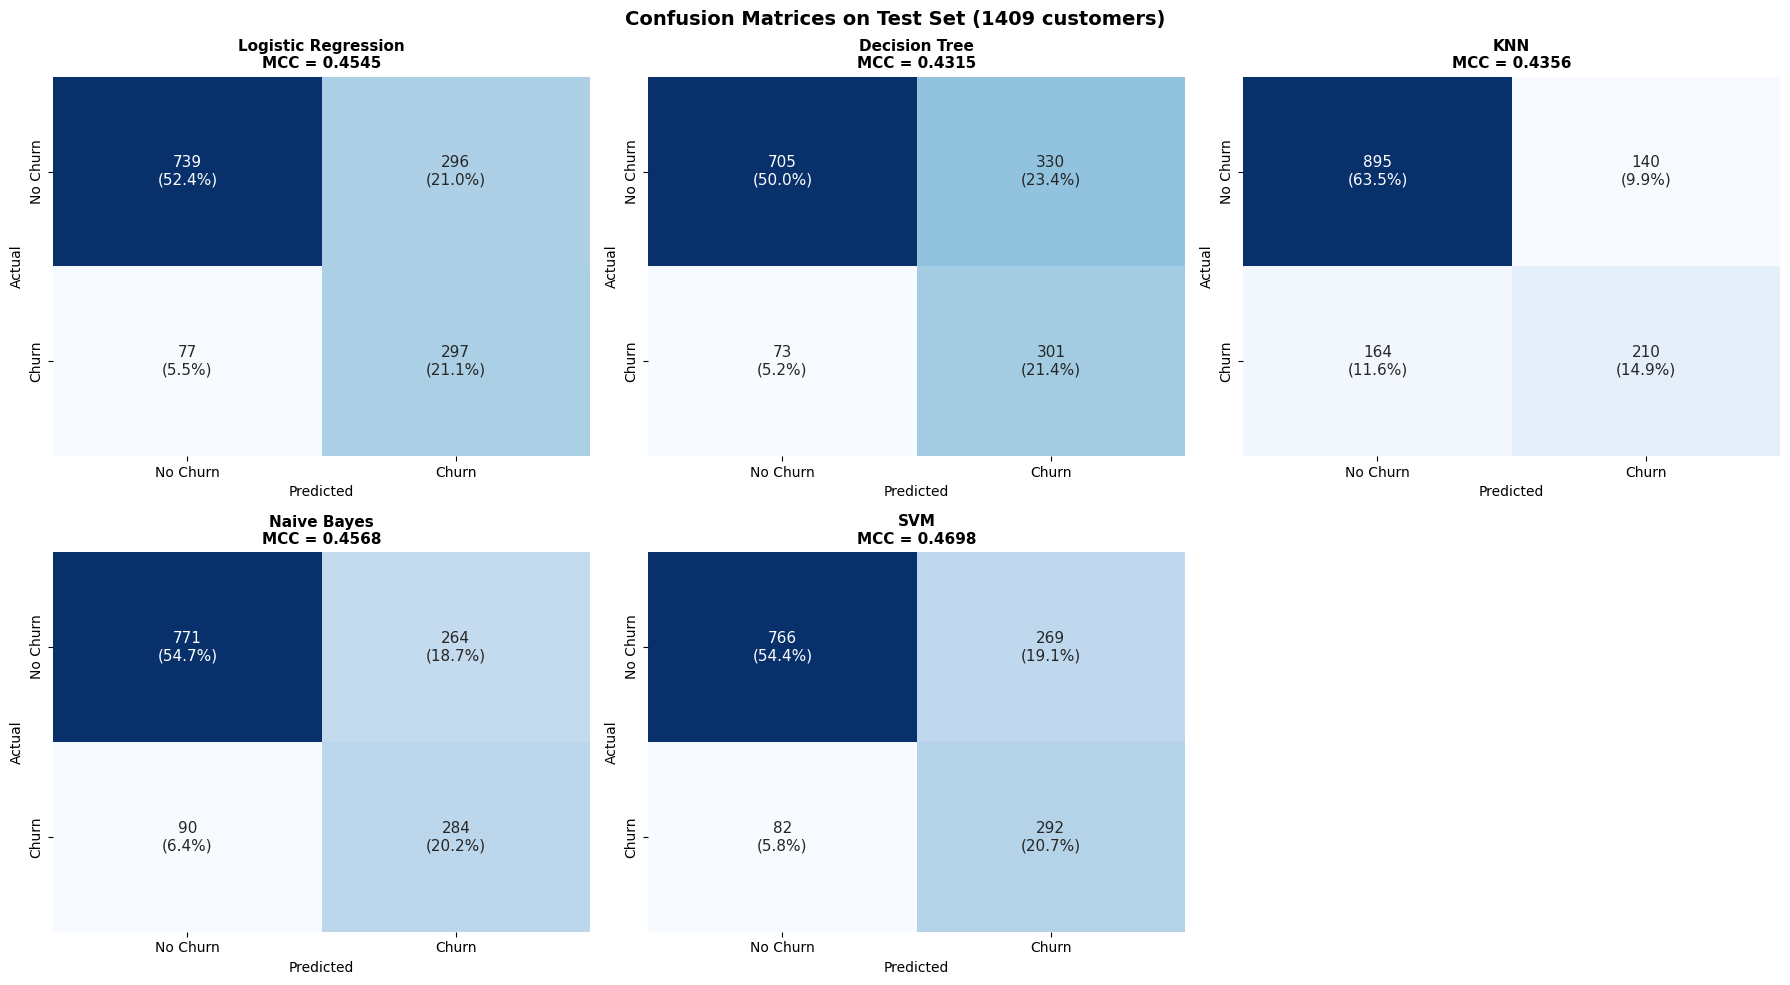

Confusion matrix counts per model:


ML Model Name,TN,FP,FN,TP
Logistic Regression,739,296,77,297
Decision Tree,705,330,73,301
KNN,895,140,164,210
Naive Bayes,771,264,90,284
SVM,766,269,82,292



Quick read:
- FN (missed churners) is the costly error for a telecom - those customers leave without any retention offer
- FP (false alarms) only costs a retention offer to someone who would have stayed anyway
- Fewest missed churners: Decision Tree (FN = 73)
- Fewest false alarms   : KNN (FP = 140)


In [0]:
# Confusion matrix of each tuned model on the test set (rows = actual, columns = predicted)
# TN top-left, FP top-right (flagged but stayed), FN bottom-left (missed churner), TP bottom-right

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()
class_labels = ['No Churn', 'Churn']

cm_summary = []
for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    # count plus % of all test rows in each box
    cell_text = np.array([[f"{v}\n({v / cm.sum() * 100:.1f}%)" for v in row] for row in cm])

    ax = axes_flat[idx]
    sns.heatmap(cm, annot=cell_text, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=class_labels, yticklabels=class_labels,
                annot_kws={'fontsize': 11})
    mcc_val = results_df.loc[results_df['ML Model Name'] == name, 'MCC'].values[0]
    ax.set_title(f"{name}\nMCC = {mcc_val:.4f}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

    cm_summary.append({'ML Model Name': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})

axes_flat[5].set_visible(False)  # only 5 models, hide the 6th subplot

plt.suptitle('Confusion Matrices on Test Set (1409 customers)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Same numbers in a table so they are easy to compare
cm_df = pd.DataFrame(cm_summary)
print("Confusion matrix counts per model:")
display(cm_df)

print("\nQuick read:")
print("- FN (missed churners) is the costly error for a telecom - those customers leave without any retention offer")
print("- FP (false alarms) only costs a retention offer to someone who would have stayed anyway")
print(f"- Fewest missed churners: {cm_df.loc[cm_df['FN'].idxmin(), 'ML Model Name']} (FN = {cm_df['FN'].min()})")
print(f"- Fewest false alarms   : {cm_df.loc[cm_df['FP'].idxmin(), 'ML Model Name']} (FP = {cm_df['FP'].min()})")

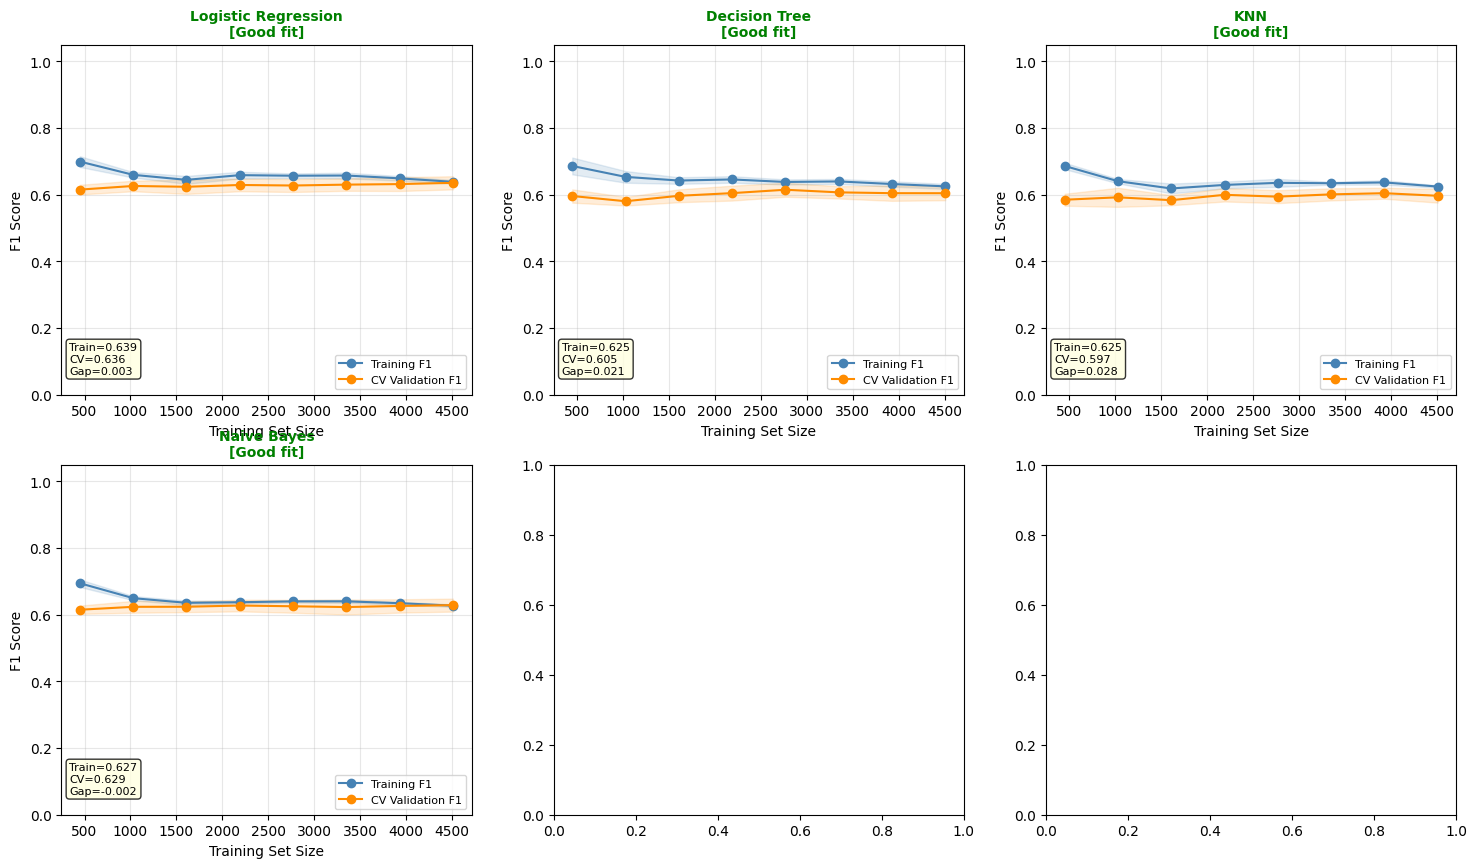

In [0]:
# Learning curves for the 5 tuned models - training F1 vs cross-validation F1 as the training size grows
# big gap at the end = overfitting, both low = underfitting, close together = good fit
# same 5-fold stratified CV as the tuning cell, so the CV scores are comparable

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()
train_sizes_pct = np.linspace(0.1, 1.0, 8)

cv_lc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tr_final_vals, v_final_vals = {}, {}   # final-point scores, used for the summary below

for idx, (name, model) in enumerate(trained_models.items()):
    ax = axes_flat[idx]

    train_sz, train_sc, val_sc = learning_curve(
        model, X_train_scaled, y_train,
        cv=cv_lc,
        train_sizes=train_sizes_pct,
        scoring='f1',
        n_jobs=-1
    )

    tr_mean = train_sc.mean(axis=1)
    tr_std  = train_sc.std(axis=1)
    v_mean  = val_sc.mean(axis=1)
    v_std   = val_sc.std(axis=1)

    ax.plot(train_sz, tr_mean, 'o-', color='steelblue',  label='Training F1')
    ax.fill_between(train_sz, tr_mean - tr_std,  tr_mean + tr_std,  alpha=0.15, color='steelblue')
    ax.plot(train_sz, v_mean,  'o-', color='darkorange', label='CV Validation F1')
    ax.fill_between(train_sz, v_mean  - v_std,   v_mean  + v_std,   alpha=0.15, color='darkorange')

    # verdict based on the last point (full training data)
    gap = tr_mean[-1] - v_mean[-1]
    if gap > 0.15:
        verdict = 'Overfitting (large gap)'
        col = 'red'
    elif v_mean[-1] < 0.45:
        verdict = 'Underfitting (both low)'
        col = 'purple'
    else:
        verdict = 'Good fit'
        col = 'green'

    ax.set_title(f'{name}\n[{verdict}]', fontsize=10, color=col, fontweight='bold')
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('F1 Score')
    ax.legend(loc='lower right', fontsize=8)
    ax.set_ylim([0.0, 1.05])
    ax.grid(True, alpha=0.3)
    # store final values for summary
    tr_final_vals[name] = float(tr_mean[-1])
    v_final_vals[name]  = float(v_mean[-1])

    ax.annotate(f'Train={tr_mean[-1]:.3f}\nCV={v_mean[-1]:.3f}\nGap={gap:.3f}',
                xy=(0.02, 0.06), xycoords='axes fraction', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# keep the last-point scores for the text summary below
lc_summary = {}
for name in trained_models.keys():
    lc_summary[name] = (tr_final_vals[name], v_final_vals[name])

axes_flat[5].set_visible(False)  

plt.suptitle('Learning Curves - Training vs CV Validation F1 Score\n'
             '(checks overfitting / underfitting for each model)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# short text summary of the same numbers
print("\nLearning curve summary (at full training data):")
for name, (tr_final, v_final) in lc_summary.items():
    gap = tr_final - v_final
    status = 'Overfitting' if gap > 0.15 else ('Underfitting' if v_final < 0.45 else 'Good fit')
    print(f"  {name:<22}: Train F1={tr_final:.4f}, CV F1={v_final:.4f}, Gap={gap:.4f} -> {status}")

In [0]:
# Observations for each model and the overall winner (picked on MCC)

# Find the best model for each metric
print("Best model for each metric:")
for metric in ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']:
    best_idx = results_df[metric].idxmax()
    best_name = results_df.loc[best_idx, 'ML Model Name']
    best_val = results_df.loc[best_idx, metric]
    print(f"  {metric}: {best_name} ({best_val:.4f})")

# Why MCC: only 26.5% of customers churn, so a model that always says 'No Churn' already gets 73.5% accuracy
# MCC uses all 4 cells of the confusion matrix (TP, TN, FP, FN) and gives 0 for that kind of model
# (+1 = perfect, 0 = no better than guessing, -1 = always wrong)
winner_idx = results_df['MCC'].idxmax()
overall_winner = results_df.loc[winner_idx, 'ML Model Name']
winner_mcc = results_df.loc[winner_idx, 'MCC']
winner_f1 = results_df.loc[winner_idx, 'F1']

print(f"\nOverall winner (primary: MCC, secondary check: F1): {overall_winner}")
print(f"  MCC = {winner_mcc:.4f}, F1 = {winner_f1:.4f}")
print("\nWhy not accuracy?")
print(f"  A model always predicting No Churn gets {(1 - y.mean()) * 100:.1f}% accuracy but MCC = 0.0")
print("  MCC rewards models that correctly identify both churners and non-churners")

print("\n" + "=" * 80)
print("Observations for Each Model")
print("=" * 80)

# MCC rank of each model (1 = best) so the observation text always matches the actual numbers
mcc_rank = results_df.set_index('ML Model Name')['MCC'].rank(ascending=False).astype(int)

def cw_text(name):
    # short note on whether class weighting was picked by the grid search
    cw = best_params[name].get('class_weight')
    return "balanced class weights" if cw == 'balanced' else "no class weighting"

observations = {}
for _, row in results_df.iterrows():
    name = row['ML Model Name']
    p = best_params[name]
    head = (f"Acc={row['Accuracy']:.4f}, MCC={row['MCC']:.4f}, F1={row['F1']:.4f}, "
            f"Recall={row['Recall']:.4f} (MCC rank {mcc_rank[name]}/5). ")
    if name == 'Logistic Regression':
        obs = head + (f"Tuned C={p['C']}, penalty={p['penalty']}, {cw_text(name)}. "
                      f"Simple linear model with a small train-test gap and easy to explain.")
    elif name == 'Decision Tree':
        obs = head + (f"Tuned max_depth={p['max_depth']}, min_samples_leaf={p['min_samples_leaf']}, {cw_text(name)}. "
                      f"Depth and leaf limits stop it from memorizing the training data.")
    elif name == 'KNN':
        obs = head + (f"Tuned n_neighbors={p['n_neighbors']}, metric={p['metric']}, weights={p['weights']}. "
                      f"Gained from removing duplicate columns, but sklearn KNN has no class weights so recall stays lower.")
    elif name == 'Naive Bayes':
        obs = head + (f"Tuned var_smoothing={p['var_smoothing']}. "
                      f"Improved the most after I dropped the duplicate dummies and took the log of TotalCharges, "
                      f"since NB assumes independent, bell-shaped features.")
    elif name == 'SVM':
        obs = head + (f"Tuned C={p['C']}, gamma={p['gamma']}, {cw_text(name)}. "
                      f"RBF kernel can pick up non-linear patterns and class weighting pushes recall up on churners.")
    observations[name] = obs
    print(f"\n{name}:")
    print(f"  {obs}")

print(f"\nOverall, Winner for this dataset: {overall_winner} (MCC = {winner_mcc:.4f})")

Best model for each metric:
  Accuracy: KNN (0.7842)
  AUC: Logistic Regression (0.8464)
  Precision: KNN (0.6000)
  Recall: Decision Tree (0.8048)
  F1: SVM (0.6246)
  MCC: SVM (0.4698)

Overall winner (primary: MCC, secondary check: F1): SVM
  MCC = 0.4698, F1 = 0.6246

Why not accuracy?
  A model always predicting No Churn gets 73.5% accuracy but MCC = 0.0
  MCC rewards models that correctly identify both churners and non-churners

Observations for Each Model

Logistic Regression:
  Acc=0.7353, MCC=0.4545, F1=0.6143, Recall=0.7941 (MCC rank 3/5). Tuned C=10, penalty=l1, balanced class weights. Simple linear model with a small train-test gap and easy to explain.

Decision Tree:
  Acc=0.7140, MCC=0.4315, F1=0.5990, Recall=0.8048 (MCC rank 5/5). Tuned max_depth=5, min_samples_leaf=20, balanced class weights. Depth and leaf limits stop it from memorizing the training data.

KNN:
  Acc=0.7842, MCC=0.4356, F1=0.5801, Recall=0.5615 (MCC rank 4/5). Tuned n_neighbors=31, metric=manhattan, we

In [0]:
# Save the 5 models, the scaler, feature names and the test data
# the Streamlit app loads these

# Save each model as a .joblib file in the model/ folder
model_filenames = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'SVM': 'svm.joblib'
}

for name, model in trained_models.items():
    filepath = os.path.join(model_dir, model_filenames[name])
    joblib.dump(model, filepath)
    print(f"Saved {name} -> {filepath}")

# Save the scaler (the Streamlit app needs this to scale uploaded data the same way)
scaler_path = os.path.join(model_dir, 'scaler.joblib')
joblib.dump(scaler, scaler_path)
print(f"Saved scaler -> {scaler_path}")

# Save feature names (so the app can verify the uploaded CSV has correct columns)
feature_names_path = os.path.join(model_dir, 'feature_names.joblib')
joblib.dump(list(X.columns), feature_names_path)
print(f"Saved feature names -> {feature_names_path}")

# Save the test data (features + target) as test_data.csv
# this is the file to upload in the Streamlit app
# features are saved unscaled because the app applies the scaler itself
test_data = X_test.copy()
test_data['target'] = y_test.values
test_csv_path = os.path.join(project_dir, 'test_data.csv')
test_data.to_csv(test_csv_path, index=False)
print(f"Saved test data -> {test_csv_path}")
print(f"Test data shape: {test_data.shape}")

print("\nAll files saved successfully!")

Saved Logistic Regression -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/logistic_regression.joblib
Saved Decision Tree -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/decision_tree.joblib
Saved KNN -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/knn.joblib
Saved Naive Bayes -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/naive_bayes.joblib
Saved SVM -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/svm.joblib
Saved scaler -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/scaler.joblib
Saved feature names -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/model/feature_names.joblib
Saved test data -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/test_data.csv
Test data shape: (1409, 24)

All files saved successfully!


In [0]:
# Write the Streamlit app (app.py)
# upload a test CSV, pick a model, see its metrics, confusion matrix, classification report and a comparison of all 5
# the app only loads the saved models from model/, nothing is retrained there

app_code = '''import streamlit as st
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

st.set_page_config(page_title="Telco Customer Churn Classification", layout="wide")

st.title("Telco Customer Churn Classification - ML Models")
st.write("Upload your test data CSV (with encoded feature columns + target column) to evaluate saved models.")


@st.cache_resource
def load_artifacts():
    model_files = {
        "Logistic Regression": "logistic_regression.joblib",
        "Decision Tree": "decision_tree.joblib",
        "KNN": "knn.joblib",
        "Naive Bayes": "naive_bayes.joblib",
        "SVM": "svm.joblib"
    }
    models = {}
    for name, fname in model_files.items():
        models[name] = joblib.load(os.path.join("model", fname))
    scaler = joblib.load(os.path.join("model", "scaler.joblib"))
    # exact feature columns (and their order) used during training
    feature_names = list(joblib.load(os.path.join("model", "feature_names.joblib")))
    return models, scaler, feature_names


models, scaler, feature_names = load_artifacts()

uploaded_file = st.file_uploader("Upload test data CSV", type=["csv"])

if uploaded_file is not None:
    test_data = pd.read_csv(uploaded_file)

    # check the uploaded CSV first: it needs the target column and every feature used in training
    has_target = "target" in test_data.columns
    missing_features = [c for c in feature_names if c not in test_data.columns]
    extra_cols = [c for c in test_data.columns if c not in feature_names and c != "target"]
    bad_target = has_target and not set(test_data["target"].dropna().unique()).issubset({0, 1})

    if not has_target or missing_features or bad_target:
        if not has_target:
            st.error("CSV must contain a target column (0 = No Churn, 1 = Churn)")
        if bad_target:
            st.error("The target column must contain only 0 and 1")
        if missing_features:
            st.error(f"CSV is missing {len(missing_features)} required feature column(s): {', '.join(missing_features)}")
        st.info(f"Expected {len(feature_names)} feature columns + target. Use test_data.csv from the repo as a template.")
    elif [c for c in feature_names if not pd.api.types.is_numeric_dtype(test_data[c])]:
        non_numeric = [c for c in feature_names if not pd.api.types.is_numeric_dtype(test_data[c])]
        st.error(f"These feature columns must be numeric (already encoded): {', '.join(non_numeric)}")
    elif test_data[feature_names + ["target"]].isnull().any().any():
        st.error("Some values are empty - please fill or remove those rows before uploading")
    else:
        if extra_cols:
            st.warning(f"Ignoring {len(extra_cols)} extra column(s) not used by the models: {', '.join(extra_cols)}")

        # Keep only the training features, in the same order the scaler and models saw in training
        X_test = test_data[feature_names]
        y_test = test_data["target"].astype(int)
        st.success(f"CSV validated: {len(test_data)} rows, {len(feature_names)} features + target")

        # show the first rows so it is clear the file was read correctly
        st.subheader("Uploaded Test Data (first 5 rows)")
        st.write(f"{test_data.shape[0]} rows x {test_data.shape[1]} columns")
        st.dataframe(test_data.head(), use_container_width=True)

        # Apply the same scaling that was used during training (keep column names, the models were fit with them)
        X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names)

        # Model selection dropdown
        st.subheader("Select Model")
        selected = st.selectbox("Choose a model to evaluate", list(models.keys()))

        model = models[selected]
        y_pred = model.predict(X_test_scaled)

        # AUC needs probability scores (all 5 saved models support predict_proba)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
        auc = roc_auc_score(y_test, y_prob)

        # Calculate all 6 metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)

        # Display evaluation metrics
        st.subheader("Evaluation Metrics")
        col1, col2, col3 = st.columns(3)
        col1.metric("Accuracy", f"{accuracy:.4f}")
        col1.metric("Precision", f"{precision:.4f}")
        col2.metric("AUC", f"{auc:.4f}")
        col2.metric("Recall", f"{recall:.4f}")
        col3.metric("F1 Score", f"{f1:.4f}")
        col3.metric("MCC", f"{mcc:.4f}")

        # Confusion matrix
        st.subheader("Confusion Matrix")
        cm = confusion_matrix(y_test, y_pred)
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=["No Churn", "Churn"],
                    yticklabels=["No Churn", "Churn"])
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix - {selected}")
        st.pyplot(fig)

        # Classification report
        st.subheader("Classification Report")
        # output_dict=True gives the report as a dict, so it can be shown as a proper table
        report = classification_report(y_test, y_pred, target_names=["No Churn", "Churn"], output_dict=True)
        report_df = pd.DataFrame(report).transpose()
        # accuracy is already shown in the metric cards above and support is just the row count,
        # so keep only the per-class and average rows with precision, recall and F1
        report_df = report_df.drop(index="accuracy").drop(columns="support")
        report_df.columns = ["Precision", "Recall", "F1-score"]
        st.dataframe(report_df.round(4), use_container_width=True)

        # All models comparison table
        st.subheader("All Models Comparison")
        all_results = []
        for name, m in models.items():
            pred = m.predict(X_test_scaled)
            prob = m.predict_proba(X_test_scaled)[:, 1]
            a = roc_auc_score(y_test, prob)
            all_results.append({
                "Model": name,
                "Accuracy": accuracy_score(y_test, pred),
                "AUC": a,
                "Precision": precision_score(y_test, pred),
                "Recall": recall_score(y_test, pred),
                "F1": f1_score(y_test, pred),
                "MCC": matthews_corrcoef(y_test, pred)
            })
        comp_df = pd.DataFrame(all_results)
        st.dataframe(comp_df.round(4), use_container_width=True)

        # Short summary built from the comparison table, so it always matches the uploaded data
        best = comp_df.loc[comp_df["MCC"].idxmax()]
        top_recall = comp_df.loc[comp_df["Recall"].idxmax()]
        churn_pct = y_test.mean() * 100
        st.subheader("Summary")
        st.markdown(f"- **Best overall model:** {best['Model']}, with the highest MCC ({best['MCC']:.4f}) and an F1 of {best['F1']:.4f} on this test data.")
        st.markdown(f"- **Catches the most churners:** {top_recall['Model']}, with a recall of {top_recall['Recall']:.4f}, useful if missing a churner costs more than a false alarm.")
        st.markdown(f"- **Why MCC decides the winner:** only {churn_pct:.1f}% of customers in this file churned, so accuracy can look good even when many churners are missed. MCC uses all four cells of the confusion matrix.")
else:
    st.info("Please upload a CSV file with the test data.")
'''

app_path = os.path.join(project_dir, "app.py")
with open(app_path, "w") as f:
    f.write(app_code)
print(f"Saved app.py -> {app_path}")
print(f"app.py contains {len(app_code)} characters")

Saved app.py -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/app.py
app.py contains 7714 characters


In [0]:
# Generate requirements.txt and README.md

# requirements.txt - list all packages the Streamlit app needs to run
# Versions are pinned to the ones used for training here - a model saved with one
import sklearn, matplotlib
requirements_content = "\n".join([
    "streamlit",
    f"scikit-learn=={sklearn.__version__}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"seaborn=={sns.__version__}",
    f"joblib=={joblib.__version__}",
]) + "\n"

req_path = os.path.join(project_dir, "requirements.txt")
with open(req_path, "w") as f:
    f.write(requirements_content)
print(f"Saved requirements.txt -> {req_path}")
print(requirements_content)

# README.md - 
# sections follow the assignment format:
# a. Problem statement
# b. Dataset description
# c. Github Repository Link
# d. Models used (comparison table + observations table + winner)
# e. Methodology notes (preprocessing, tuning, learning curves, metric choice)

# model names as written in the assignment table
model_name_map = {
    "Logistic Regression": "Logistic Regression",
    "Decision Tree": "Decision Tree",
    "KNN": "KNN",
    "Naive Bayes": "Naive Bayes",
    "SVM": "Support Vector Machine"
}

# Build the comparison table
comp_header = "| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |\n| --- | --- | --- | --- | --- | --- | --- |"
comp_rows = ""
for _, row in results_df.iterrows():
    display_name = model_name_map.get(row["ML Model Name"], row["ML Model Name"])
    comp_rows += f"\n| {display_name} | {row['Accuracy']:.4f} | {row['AUC']:.4f} | {row['Precision']:.4f} | {row['Recall']:.4f} | {row['F1']:.4f} | {row['MCC']:.4f} |"

# Build the observations table
obs_header = "| ML Model Name | Observation about model performance |\n| --- | --- |"
obs_rows = ""
for _, row in results_df.iterrows():
    display_name = model_name_map.get(row["ML Model Name"], row["ML Model Name"])
    obs_rows += f"\n| {display_name} | {observations[row['ML Model Name']]} |"
obs_rows += f"\n| Overall, Winner for your dataset? | {overall_winner} (highest MCC = {winner_mcc:.4f}) |"

# Build the hyperparameter tuning table (best params + best 5-fold CV MCC from GridSearchCV)
cv_best_scores = {
    'Logistic Regression': lr_grid.best_score_,
    'Decision Tree': dt_grid.best_score_,
    'KNN': knn_grid.best_score_,
    'Naive Bayes': nb_grid.best_score_,
    'SVM': svm_grid.best_score_
}
search_space = {
    'Logistic Regression': 'C: [0.01, 0.1, 1, 10, 100], penalty: [l1, l2], class_weight: [None, balanced]',
    'Decision Tree': 'max_depth: [3, 5, 7, 10, None], min_samples_split: [2, 5, 10], min_samples_leaf: [1, 5, 10, 20], criterion: [gini, entropy], class_weight: [None, balanced]',
    'KNN': 'n_neighbors: [11, 15, 21, 25, 31, 41], weights: [uniform, distance], metric: [euclidean, manhattan]',
    'Naive Bayes': 'var_smoothing: [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]',
    'SVM': 'C: [0.5, 1, 2, 5], gamma: [scale, auto], class_weight: [None, balanced] (RBF kernel)'
}
tune_header = "| ML Model Name | Search Space | Best Params | Best CV MCC |\n| --- | --- | --- | --- |"
tune_rows = ""
for name in best_params:
    params_str = ", ".join(f"{k}={v}" for k, v in best_params[name].items())
    tune_rows += f"\n| {model_name_map[name]} | {search_space[name]} | {params_str} | {cv_best_scores[name]:.4f} |"

# Build the learning curve (overfitting check) table from lc_summary
lc_header = "| ML Model Name | Train F1 | CV F1 | Gap | Verdict |\n| --- | --- | --- | --- | --- |"
lc_rows = ""
for name, (tr_final, v_final) in lc_summary.items():
    gap = tr_final - v_final
    status = 'Overfitting' if gap > 0.15 else ('Underfitting' if v_final < 0.45 else 'Good fit')
    lc_rows += f"\n| {model_name_map[name]} | {tr_final:.4f} | {v_final:.4f} | {gap:.4f} | {status} |"

readme_content = f"""# ML Assignment 2 - Classification Models and Streamlit Deployment

## a. Problem Statement

A telecom company loses revenue every time a customer cancels their service (churns), and keeping an existing customer is usually much cheaper than finding a new one. In this dataset about 26.5% of the 7043 customers have churned. The goal of this project is to predict, from a customer's account details, services and billing information (contract type, tenure, monthly charges, internet service, payment method, etc.), whether that customer is likely to churn. The company could then target those customers with retention offers before they leave.

Because churners are the minority class, a model that simply predicts "No Churn" for everyone would still look about 73.5% accurate. The model therefore has to identify actual churners well, not just score high on accuracy. To find the best approach, 5 classification models (Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM) are trained on the same data and compared on 6 metrics (Accuracy, AUC, Precision, Recall, F1, MCC). A Streamlit app is deployed so the saved models can be evaluated on new test data without retraining.

## b. Dataset Description

- **Name:** Telco Customer Churn
- **Source:** Kaggle (https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Features:** 20 columns (customerID + 18 features + Churn target), cleaned and one-hot encoded to 23 features after dropping customerID
- **Instances:** 7043 (5174 stayed, 1869 churned)
- **Target:** Binary classification (0 = No Churn, 1 = Churn)
- **Feature types:** Numeric (tenure, MonthlyCharges, TotalCharges) and categorical (Contract, PaymentMethod, InternetService, etc.)

## c. GitHub Repository Link

https://github.com/deepakshekhawat1209/ML_Classification_BITS.git

## d. Models Used

{comp_header}{comp_rows}

### Observations

{obs_header}{obs_rows}

## e. Methodology Notes

### Preprocessing

- Dropped customerID (identifier), converted TotalCharges to numeric (11 blank values filled with 0)
- One-hot encoded 15 categorical columns with drop_first=True, giving 30 columns
- Removed 7 duplicate dummies: the 6 `*_No internet service` columns are identical to `InternetService_No`, and `MultipleLines_No phone service` equals 1 - `PhoneService_Yes`. This leaves 23 features
- Log-transformed TotalCharges (log1p) because it is heavily right-skewed
- 80/20 stratified train-test split (5634 train, 1409 test), StandardScaler fitted on training data only

### Hyperparameter Tuning

All 5 models were tuned with GridSearchCV using 5-fold StratifiedKFold on the training set. Stratified folds keep the 73.5 / 26.5 churn ratio in every fold. MCC was used as the scoring metric, the same metric used to pick the winner, because accuracy is misleading on imbalanced data. For Logistic Regression, Decision Tree and SVM the grid also chose between no class weighting and `class_weight='balanced'`, which gives the minority churn class more weight. Balanced weighting trades some accuracy and precision for much higher recall, which is the right trade for churn: a missed churner is lost revenue, a false alarm only costs a retention offer.

{tune_header}{tune_rows}

### Overfitting Check (Learning Curves)

Learning curves (training F1 vs 5-fold CV F1 over increasing training sizes) were plotted for every tuned model. A gap above 0.15 is treated as overfitting, and a CV F1 below 0.45 as underfitting.

{lc_header}{lc_rows}

### Metric Used to Pick the Winner

The winner is picked on MCC (Matthews Correlation Coefficient). With 73.5% non-churners, a model that always predicts No Churn gets 73.5% accuracy but MCC = 0. MCC uses all four cells of the confusion matrix (TP, TN, FP, FN), so it only rewards models that actually separate churners from non-churners. F1 is used as a secondary check.
"""

readme_path = os.path.join(project_dir, "README.md")
with open(readme_path, "w") as f:
    f.write(readme_content)
print(f"Saved README.md -> {readme_path}")
print("\n--- README.md Preview ---")
print(readme_content)

Saved requirements.txt -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/requirements.txt
streamlit
scikit-learn==1.7.2
numpy==2.3.4
pandas==2.3.3
matplotlib==3.10.6
seaborn==0.13.2
joblib==1.5.2

Saved README.md -> /Volumes/ebi_eads/dniran324/aiml/ML/assignment2_project/README.md

--- README.md Preview ---
# ML Assignment 2 - Classification Models and Streamlit Deployment

## a. Problem Statement

A telecom company loses revenue every time a customer cancels their service (churns), and keeping an existing customer is usually much cheaper than finding a new one. In this dataset about 26.5% of the 7043 customers have churned. The goal of this project is to predict, from a customer's account details, services and billing information (contract type, tenure, monthly charges, internet service, payment method, etc.), whether that customer is likely to churn. The company could then target those customers with retention offers before they leave.

Because churners are the minority clas